In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.patches import Rectangle
from scipy import stats
import json
import sys
import seaborn as sns

a4_x, a4_y = (8.27, 11.69)

sys.path.append('data/')
from molar_mass import molar_masses

def get_isotope_data():
    '''Reads isotope data'''
    data = pd.read_csv('data/isotope_data.csv')
    data_steep = pd.read_csv('data/steep_rock_isotopes.csv')
    # drop duplicates keeping first:
    duplicates = data.drill_core[data.drill_core.duplicated()]
    duplicates_idxs = duplicates.index
    data = data.drop(duplicates_idxs)

    data = data[['drill_core', 'd13c_sp', 'd18o_sp', 'texture']]
    data = data.rename(columns={'drill_core': 'Sample Name'})

    data_steep = data_steep[['Sample', 'd13C', 'd18O', 'Textures']]
    data_steep.columns = ['Sample Name', 'd13c_sp', 'd18o_sp', 'texture']

    data = pd.concat([data, data_steep])
    return data

def get_PAAS_data():
    paas = pd.read_csv('data/PAAS_TaylorMcLennan1985.csv')

    # get CaO concentration
    CaO_pct = float(paas[paas['var']=='CaO']['value'].iloc[0]) # units: %
    # convert to ppm (1pct = 1e4 ppm)
    CaO_ppm = CaO_pct * 1e4
    # get Ca ppm
    Ca_ppm = CaO_ppm * (molar_masses['Ca']/(molar_masses['Ca'] + molar_masses['O']))

    # get MgO concentration
    MgO_pct = float(paas[paas['var']=='MgO']['value'].iloc[0]) # units: %
    # convert to ppm
    MgO_ppm = MgO_pct * 1e4
    # get Mg ppm
    Mg_ppm = MgO_ppm * (molar_masses['Mg']/(molar_masses['Mg'] + molar_masses['O']))

    # get Al2O3 concentration
    Al2O3_pct = float(paas[paas['var']=='Al2O3']['value'].iloc[0]) # units: %
    # convert to ppm (1pct = 1e4 ppm)
    Al2O3_ppm = Al2O3_pct * 1e4
    # get Al ppm
    Al_ppm = Al2O3_ppm * ((2*molar_masses['Al'])/(2*molar_masses['Al'] + 3*molar_masses['O']))

    # filter REE data
    elements = ['La','Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb',
                'Dy', 'Y', 'Ho', 'Er', 'Tm', 'Yb', 'Lu']
    element_order = {elements[i]:i for i in range(len(elements))}

    paas = paas[paas['var'].isin(elements)]
    paas = paas[['var', 'value']]
    paas = paas.rename(columns={'var':'element', 'value':'ppm'})
    paas = paas.astype({'ppm':float})

    # convert to mol/L. 1ppm = 1 mg/l; 1mg/l = 1e-3g/l
    Ca_mol_per_l =  1e-3 * Ca_ppm/molar_masses['Ca']
    Mg_mol_per_l = 1e-3 * Mg_ppm/molar_masses['Mg']
    Al_mol_per_l = 1e-3 * Al_ppm/molar_masses['Al']
 
    paas['molar_mass'] = paas.element.map(molar_masses)
    paas['mol_per_l'] = 1e-3 * paas.ppm / paas.molar_mass

    # normalize to Ca + Mg
    paas['paas/Ca+Mg_mol_per_mol'] = paas.mol_per_l / (Ca_mol_per_l + Mg_mol_per_l)
    Al_over_Ca_Mg= Al_mol_per_l / (Ca_mol_per_l + Mg_mol_per_l)

    # normalize to Al
    paas['paas/Ca+Mg/Al_mol_per_mol'] = paas['paas/Ca+Mg_mol_per_mol']/ Al_over_Ca_Mg

    paas['Al_ppm'] = Al_ppm
    paas['Ca_ppm'] = Ca_ppm
    paas['Mg_ppm'] = Mg_ppm

    # sort elements
    paas['element_oder'] = paas['element'].map(element_order)
    paas = paas.sort_values('element_oder')
    return paas


def get_data_mol_per_mol():
    '''Reads data in mol per mol (Ca+Mg) units and calculates cerium anomalies
    and other ratios'''
    # read reduced data
    nitric_runs = pd.read_csv('data/nitric_acid_runs_reduced.csv')
    stabilizer_runs = pd.read_csv('data/stabilizer_runs_reduced.csv')

    # filter columns of interest
    nitric_runs = nitric_runs[['is_sample', 'Sample Name', 'element',
        'element_description', 'complete_sample_name', 'is_blank', 'is_sample_blank',
        'is_standard', 'has_iodine', 'inferred_mol/mol', 'run_id']]

    nitric_runs = nitric_runs[nitric_runs.element != 'I']

    stabilizer_runs = stabilizer_runs[['is_sample', 'Sample Name', 'element',
        'element_description', 'complete_sample_name', 'is_blank', 'is_sample_blank',
        'is_standard', 'has_iodine', 'inferred_mol/mol', 'run_id']]

    data = pd.concat([nitric_runs, stabilizer_runs]).reset_index(drop=1)
    data = data[(data.is_sample)&(~data.is_standard)]

    # drop duplicated and keep minimum concentration
    data = data.sort_values(['inferred_mol/mol']).drop_duplicates(
        subset=['Sample Name', 'element_description'], keep='first')
    
    iodine_samples = data[data.has_iodine]['Sample Name'].unique()
    
    data = data.pivot_table(values='inferred_mol/mol',
        columns='element_description', index=['Sample Name']).reset_index()
    
    has_iodine = lambda x: True if x in iodine_samples else False
    data['has_iodine'] = data['Sample Name'].apply(has_iodine)
    
    # cahnge espanola sample names
    change_names = lambda x: x.replace('18-2-', '')
    data['Sample Name'] = data['Sample Name'].apply(change_names)

    def starts_with_num(x):
        try:
            int(x[0])
        except:
            return False
        return True

    def assign_formation(sample_name):
        if sample_name.startswith('SR'):
            return 'Steep Rock'
        elif sample_name.startswith('B'):
            return 'Gordon Lake'
        elif starts_with_num(sample_name):
            return 'Espanola'
        else:
            return 'Not sample'
        
    # assign formation names
    data['formation'] = data['Sample Name'].apply(assign_formation)

    data = data[data['formation'] != 'Not sample']
    data = data[~data['Sample Name'].isin(['BRQ5-1 redo', 'BRQ5-1-unknown'])]

    # calculate total REE
    REE = ['La','Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er',
        'Tm', 'Yb', 'Lu']
    
    REE_cols = []
    for col in data.columns:
        for ree in REE:
            if ree in col:
                REE_cols.append(col)

    total_REE = 0
    for col in REE_cols:
        total_REE = total_REE + data[col]

    data['total_REE'] = total_REE

    # calculate Ce anomalies
    Ce, Pr, Nd = '140  Ce  [ No Gas ]', '141  Pr  [ No Gas ]', '146  Nd  [ No Gas ]'

    # normalize to PAAS
    paas = get_PAAS_data()
    paas_Ce = paas[paas.element == 'Ce']['paas/Ca+Mg_mol_per_mol'].values[0]
    paas_Nd = paas[paas.element == 'Nd']['paas/Ca+Mg_mol_per_mol'].values[0]
    paas_Pr = paas[paas.element == 'Pr']['paas/Ca+Mg_mol_per_mol'].values[0]
    Ce_norm = data[Ce]/paas_Ce
    Nd_morm = data[Nd]/paas_Nd
    Pr_morm = data[Pr]/paas_Pr

    # calculate cerium anomalies. Eqs 7, 9 from Barrat 2023
    # geometric extrapolation
    data['Ce_anomaly_geom'] = Ce_norm / (Pr_morm**2 / Nd_morm) 
    # linear extrapolation
    data['Ce_anomaly_lin'] = Ce_norm / (2 * Pr_morm - Nd_morm) 
    data['neg_Ce_anomaly'] = data['Ce_anomaly_geom'] < 0.9
    data['pos_Ce_anomaly'] = data['Ce_anomaly_geom'] > 1.1

    # carbonate richness flag
    carbonate_richness = []
    Al_str = '27  Al  [ No Gas ]'
    for i, row in data.iterrows():
        if row.formation == 'Gordon Lake':
            if row[Al_str] < 0.01:
                carbonate_richness.append(True)
            else:
                carbonate_richness.append(False)
        elif row.formation == 'Espanola':
            if row[Al_str] < 0.04:
                carbonate_richness.append(True)
            else:
                carbonate_richness.append(False)
        elif row.formation == 'Steep Rock':
            carbonate_richness.append(True)
    data['is_carbonate_rich'] = carbonate_richness
    
    # Carbonate classification based on Mg/Ca ratio
    data['Mg/Ca'] = data['25 -> 25  Mg  [ H2 ]'] /\
        data['44  Ca  [ No Gas ]']
    
    # def classify_carbonates(MgCa_ratio):
    #     if MgCa_ratio >= 0.8:
    #         return 'Dolomite'
    #     elif MgCa_ratio >= 0.3 and MgCa_ratio < 0.8:
    #         return 'Ankerite'
    #     else:
    #         return 'Calcite'
    # data['carbonate_type'] = data['Mg/Ca'].apply(classify_carbonates)

    # Y/Ho ratios
    data['Y/Ho'] = data['89  Y  [ No Gas ]'] / data['165  Ho  [ No Gas ]']

    # # set iodine = 0
    # I = []
    # for i,row in data.iterrows():

    #     if row.has_iodine:
    #         I.append(row['127  I  [ No Gas solution ]'])
    #     else:
    #         I.append(0)
    # data['127  I  [ No Gas solution ]'] = I

    # get isotope data
    isotope_data =get_isotope_data()
    isotope_data['formation'] = isotope_data['Sample Name'].apply(assign_formation)

    data = pd.merge(isotope_data, data,
        on=['Sample Name', 'formation'], how='right')
    
    # filter out veins and clasts
    data = data[~data.texture.isin(['vein ', 'clast', 'Late_stage_vein'])]

    # Filter samples with weird values
    # 9-1 has a very negative d13C (-15)
    # 19-6 has a weird REE pattern
    data = data[~data['Sample Name'].isin(['19-6', 'BRQ3-1', '9-1'])]
    
    return data

# get data in mol per mol units
all_data = get_data_mol_per_mol()
# filter out aluminum rich samples
all_data = all_data[all_data.is_carbonate_rich]
# save to csv file
all_data.to_csv('sample_data_mol_per_mol.csv', index=False)

# split by Formation
data_espanola = all_data[all_data.formation == 'Espanola']
data_gl = all_data[all_data.formation == 'Gordon Lake']
data_steep = all_data[all_data.formation == 'Steep Rock']


/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/155441938.py:97: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  nitric_runs = pd.read_csv('data/nitric_acid_runs_reduced.csv')


/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/867504022.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/867504022.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/867504022.py:14: SettingWithCopyWarning: 
A value is tr

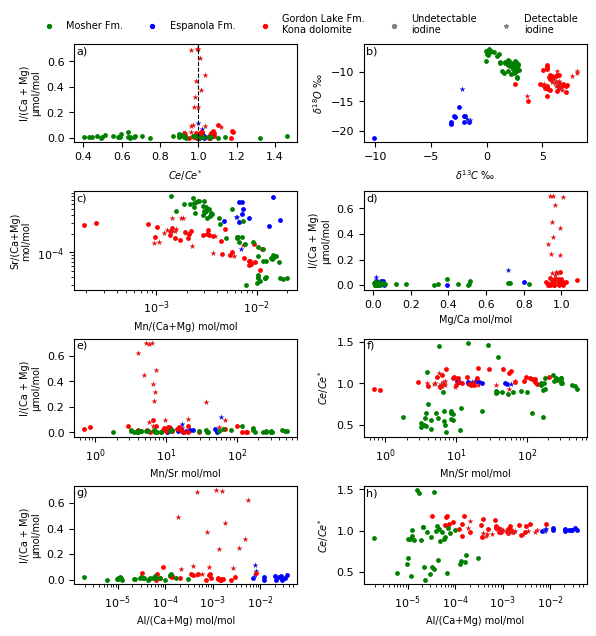

In [2]:
# Make cross plots of some variables
matplotlib.rc('xtick', labelsize=8) 
matplotlib.rc('ytick', labelsize=8)

# size of figure to fit in a4 page size
a4_x, a4_y = (8.27, 11.69)
I_str = '127  I  [ No Gas solution ]'

def plot_data(x, y, only_iodine=False, s=6):
    df_list = [data_espanola, data_gl, data_steep]
    colors = ['b', 'r', 'g']
    factor = 1e6 if y == I_str else 1
    for i, df in enumerate(df_list):
        df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
        df_iodine = df[df.has_iodine]
        df_no_iodine = df[~df.has_iodine]
        if not only_iodine:
            plt.scatter(df_no_iodine[x], df_no_iodine[y]*factor,
                color=colors[i], s=s)
        plt.scatter(df_iodine[x], df_iodine[y]*factor,
            color=colors[i], s=s*3, marker='*', edgecolor='gray', linewidth=0.1)
        
# variables to include in cross pots
vars = [
    ('Ce_anomaly_geom', I_str), 
    ('d13c_sp', 'd18o_sp'), 
    ('55 -> 55  Mn  [ H2 ]', '88  Sr  [ No Gas ]'), 
    ('Mg/Ca', I_str),
    ('Mn/Sr', I_str),
    ('Mn/Sr', 'Ce_anomaly_geom'),
    ('27  Al  [ No Gas ]', I_str), 
    # ('total_REE', I_str),
    ('27  Al  [ No Gas ]', 'Ce_anomaly_geom'), 
    # ('total_REE', 'Ce_anomaly_geom'), 
    ]

# x and y labels
labels = [
    (r'$Ce/Ce^{*}$', 'I/(Ca + Mg)\nµmol/mol'),
    (r'$\delta^{13}C$ ‰', r'$\delta^{18}O$ ‰'), 
    ('Mn/(Ca+Mg) mol/mol', 'Sr/(Ca+Mg)\nmol/mol'), 
    ('Mg/Ca mol/mol','I/(Ca + Mg)\nµmol/mol'),
    ('Mn/Sr mol/mol', 'I/(Ca + Mg)\nµmol/mol'),
    ('Mn/Sr mol/mol', r'$Ce/Ce^{*}$'),
    ('Al/(Ca+Mg) mol/mol', 'I/(Ca + Mg)\nµmol/mol'),
    # (r'$\sum$ REE/(Ca + Mg)', 'I/(Ca + Mg)\nµmol/mol'),
    ('Al/(Ca+Mg) mol/mol', r'$Ce/Ce^{*}$'),
    # (r'$\sum$ REE/(Ca + Mg)', r'$Ce/Ce^{*}$'),

    ]

# x and y scales
scales = [('linear', 'linear'),
    ('linear', 'linear'),
    ('log', 'log'),
    ('linear', 'linear'),
    ('log', 'linear'),
    ('log', 'linear'),
    ('log', 'linear'),
    ('log', 'linear'),
# ('log', 'linear'),
# ('log', 'linear'),
    ]

# plot letters
letters = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']

fig, axs = plt.subplots(4,2, figsize=(a4_x*0.8, a4_y*0.6))
axs = axs.flatten()

for i, ax in enumerate(axs):
    plt.sca(ax)

    ax.text(0.01, 0.9, letters[i], transform=ax.transAxes, size=8);
    plot_data(vars[i][0], vars[i][1])
    plt.ylabel(labels[i][1], fontsize=7)
    plt.xlabel(labels[i][0], fontsize=7)
    plt.xscale(scales[i][0])
    plt.yscale(scales[i][1])

    if i == 0:
         plt.axvline(1, color='k', ls='--', lw=0.8)
    
# make a legend
def make_handles(m,c,s, alpha=None, edgecolor=None, linewidth=None):
        return plt.scatter([],[],marker=m, s=s, color=c, alpha=alpha,
             edgecolor=None, linewidth=None)
handles = [make_handles("o","g", 8)] + [make_handles("o","b", 8)]  +\
    [make_handles("o","r", 8)] + [make_handles("o","gray", 8)] +\
    [make_handles("*","gray", 8)] 

legend_labels =[ "Mosher Fm.", "Espanola Fm.", "Gordon Lake Fm.\nKona dolomite", "Undetectable\niodine",
    'Detectable\niodine']
plt.sca(axs[0])
plt.legend(handles, legend_labels, fontsize=7, frameon=0,
    loc='upper center', ncol=5, bbox_to_anchor=(1.05, 1.4))

plt.subplots_adjust(hspace=0.5, wspace=0.3)
 

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/867504022.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/867504022.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']


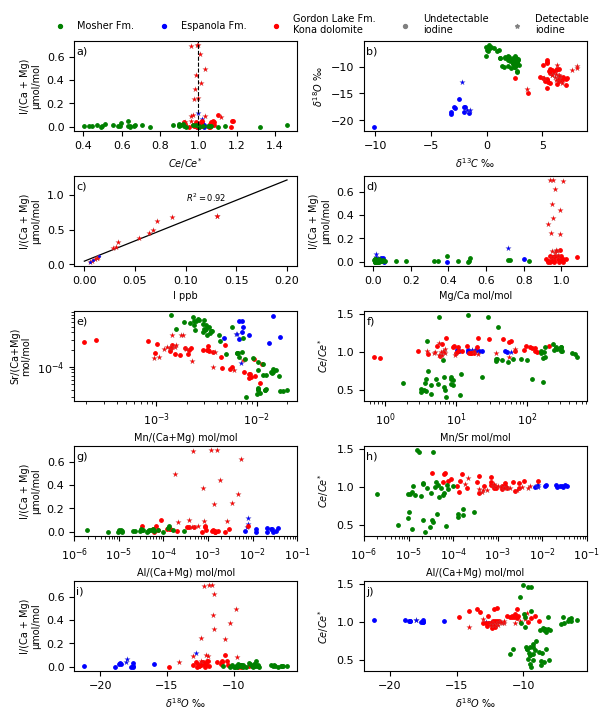

In [3]:
def I_vs_I():
    '''
    Plots I ppm vs I/(Ca+Mg)
    '''
    all_samples = all_data['Sample Name'].unique()
    samples_gl = data_gl['Sample Name'].unique()
    samples_esp = data_espanola['Sample Name'].unique()

    # cahnge espanola sample names
    change_names = lambda x: x.replace('18-2-', '')
    
    # read I data in mol per mol units
    stabilizer_runs = pd.read_csv('data/stabilizer_runs_reduced.csv')
    # change Espnola sample names
    stabilizer_runs['Sample Name'] = stabilizer_runs['Sample Name'].apply(change_names)
    # filter I data
    stabilizer_runs = stabilizer_runs[
        stabilizer_runs.element_description == '127  I  [ No Gas solution ]']
    # filter samples above detection limt
    stabilizer_runs = stabilizer_runs[stabilizer_runs.has_iodine]
    # filter samples
    stabilizer_runs = stabilizer_runs[stabilizer_runs['Sample Name'].isin(all_samples)]

    # read data in ppm units
    stabilizer_runs_ppb = pd.read_csv('data/stabilizer_runs_reduced_ppb.csv')
     # change Espnola sample names
    stabilizer_runs_ppb['Sample Name'] = stabilizer_runs_ppb['Sample Name'].apply(change_names)
    # filter I data
    stabilizer_runs_ppb = stabilizer_runs_ppb[
        stabilizer_runs_ppb.element_description == '127  I  [ No Gas solution ]']
    # filter samples above detection limt
    stabilizer_runs_ppb = stabilizer_runs_ppb[stabilizer_runs_ppb.has_iodine]
    stabilizer_runs_ppb = stabilizer_runs_ppb[stabilizer_runs_ppb['Sample Name'].isin(all_samples)]


    x =  stabilizer_runs_ppb['inferred_ppb_zero_intercept']
    y = stabilizer_runs['inferred_mol/mol']*1e6 # convert to micro mol/mol

    # make a liner regression line
    regress_params = stats.linregress(x, y)
    m = regress_params[0]
    b = regress_params[1]
    r2 = round(regress_params[2]**2, 2)
    x_regress = np.linspace(0, 0.2, 34)
    y_regress = m*x_regress + b

    # plot i data
    sample_list = [samples_gl, samples_esp]
    colors = ['r', 'b']
    markers = ['*', '.']
    for i, samples in enumerate(sample_list):
        stabilizer_runs_ =\
            stabilizer_runs[stabilizer_runs['Sample Name'].isin(samples)]
        stabilizer_runs_ppb_ =\
            stabilizer_runs_ppb[stabilizer_runs_ppb['Sample Name'].isin(samples)]
        
        x_ =  stabilizer_runs_ppb_['inferred_ppb_zero_intercept']
        y_ = stabilizer_runs_['inferred_mol/mol']*1e6

        plt.scatter(x_, y_, color=colors[i], marker=markers[i], s=18, zorder=7,
                     edgecolor='gray', linewidth=0.1)
    plt.plot(x_regress, y_regress, color='k', zorder=0, lw=0.9)
    plt.text(0.1, 0.91, r'$R^2=$' + str(r2), fontsize=6)
        
# variables included in cross plots
vars = [
    ('Ce_anomaly_geom', I_str), 
    ('d13c_sp', 'd18o_sp'), 
    ('I_vs_I', 'I_vs_I'),
    ('Mg/Ca', I_str),
    # ('Mn/Sr', I_str),
    ('55 -> 55  Mn  [ H2 ]', '88  Sr  [ No Gas ]'), 
    ('Mn/Sr', 'Ce_anomaly_geom'),
    ('27  Al  [ No Gas ]', I_str), 
    # ('total_REE', I_str),
    ('27  Al  [ No Gas ]', 'Ce_anomaly_geom'), 
    # ('total_REE', 'Ce_anomaly_geom'), 
    ('d18o_sp', I_str),
    ('d18o_sp', 'Ce_anomaly_geom'),
    ]

# x and y lables
labels = [
    (r'$Ce/Ce^{*}$', 'I/(Ca + Mg)\nµmol/mol'),
    (r'$\delta^{13}C$ ‰', r'$\delta^{18}O$ ‰'), 
    ('I ppb', 'I/(Ca + Mg)\nµmol/mol'), 
    ('Mg/Ca mol/mol','I/(Ca + Mg)\nµmol/mol'),
    # ('Mn/Sr mol/mol', 'I/(Ca + Mg)\nµmol/mol'),
    ('Mn/(Ca+Mg) mol/mol', 'Sr/(Ca+Mg)\nmol/mol'), 
    ('Mn/Sr mol/mol', r'$Ce/Ce^{*}$'),
    ('Al/(Ca+Mg) mol/mol', 'I/(Ca + Mg)\nµmol/mol'),
    # (r'$\sum$ REE/(Ca + Mg)', 'I/(Ca + Mg)\nµmol/mol'),
    ('Al/(Ca+Mg) mol/mol', r'$Ce/Ce^{*}$'),
    # (r'$\sum$ REE/(Ca + Mg)', r'$Ce/Ce^{*}$'),
    (r'$\delta^{18}O$ ‰',  'I/(Ca + Mg)\nµmol/mol'),
     (r'$\delta^{18}O$ ‰',  r'$Ce/Ce^{*}$')
    ]

# x and y scales
scales = [('linear', 'linear'),
    ('linear', 'linear'),
    ('linear', 'linear'),
    ('linear', 'linear'),
    ('log', 'log'),
    ('log', 'linear'),
    ('log', 'linear'),
    ('log', 'linear'),
# ('log', 'linear'),
# ('log', 'linear'),
    ('linear', 'linear'),
    ('linear', 'linear'),
    ]

#  plot letters
letters = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)', 'i)', 'j)']

# make cross plots
fig, axs = plt.subplots(5,2, figsize=(a4_x*0.8, a4_y*0.7))
axs = axs.flatten()

for i, ax in enumerate(axs):
    plt.sca(ax)
    if vars[i][0] == 'I_vs_I':
        ax.text(0.01, 0.85, letters[i], transform=ax.transAxes, size=8);
        I_vs_I()
    # elif i==4:
    #     ax.text(0.93, 0.85, letters[i], transform=ax.transAxes, size=8);
    #     plot_data(vars[i][0], vars[i][1])
    else:
        ax.text(0.01, 0.85, letters[i], transform=ax.transAxes, size=8);
        plot_data(vars[i][0], vars[i][1])
    plt.ylabel(labels[i][1], fontsize=7)
    plt.xlabel(labels[i][0], fontsize=7)
    plt.xscale(scales[i][0])
    plt.yscale(scales[i][1])

    if i in [6, 7]:
        plt.xlim([1e-6,1e-1])

    if i == 0:
         plt.axvline(1, color='k', ls='--', lw=0.8)
    
    # if i ==1:
    #     # plt.xlim([-5,10])
    #     # plt.ylim([-25,0])


plt.sca(axs[0])
plt.legend(handles, legend_labels, fontsize=7, frameon=0,
    loc='upper center', ncol=5, bbox_to_anchor=(1.1, 1.4))

plt.subplots_adjust(hspace=0.5, wspace=0.3)
# plt.tight_layout()
plt.savefig('plots/cross_plots.pdf')

 

    


/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/1125227822.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/1125227822.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['I_mumol'] = df[I_str] * 1e6
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/1125227822.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a sli

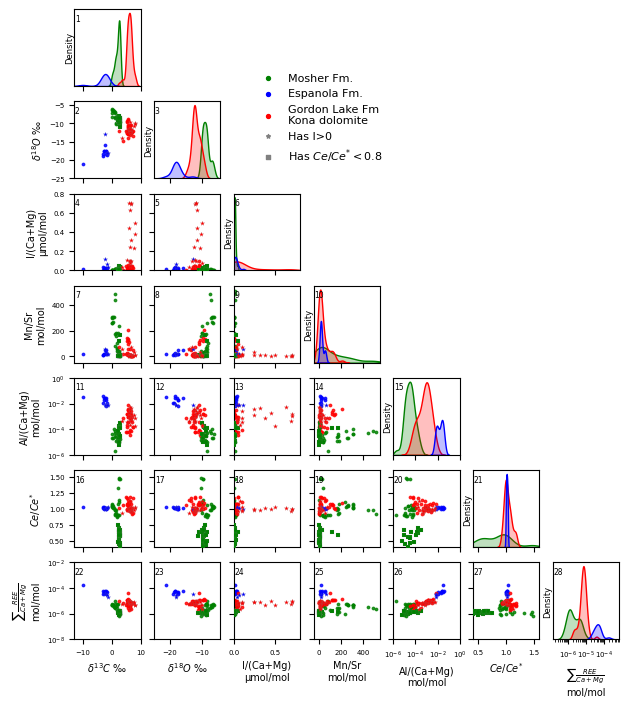

In [4]:
# Make cross plots triangle with density plots 

matplotlib.rc('xtick', labelsize=5) 
matplotlib.rc('ytick', labelsize=5)

fig, axs = plt.subplots(7, 7, figsize=(a4_x*0.85, a4_y*0.7),
                        sharex="col",
                            squeeze=False)

# Make triangle
hide_indices = np.triu_indices_from(axs, 1)
for i, j in zip(*hide_indices):
    axs[i, j].remove()
    axs[i, j] = None


def plot_data(x, y, only_iodine=False, s=3):
    '''Makes a cross plot'''
    # datasets
    df_list = [data_steep, data_espanola, data_gl]
    # formations
    labels = ['Steep Rock Fm.', 'Espanola Fm.', 'Gordon Lake Fm.']
    # color for each formation
    colors = ['g', 'b', 'r']

    for i, df in enumerate(df_list):
        # calculate Mn/Sr ratio
        df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
        # convert to micro mol/mol
        df['I_mumol'] = df[I_str] * 1e6
        # for mosher samples plot data with and without ce anomalies with
        #  different markers
        if i ==0:
            df_neg = df[df.Ce_anomaly_geom < 0.8]
            df_no_neg =  df[df.Ce_anomaly_geom >= 0.8]
           
            plt.scatter(df_no_neg[x], df_no_neg[y],
                color=colors[i], s=s, label= labels[i], alpha=0.8, zorder=0)

            plt.scatter(df_neg[x], df_neg[y],
                color=colors[i], s=s*1.9, marker='s', edgecolor='gray', 
                linewidth=0.08, zorder=5)
        # for espanola and gordon lake samples plot data with and without I with
        #  different markers
        else:
            df_iodine = df[df.has_iodine]
            df_no_iodine = df[~df.has_iodine]
            if not only_iodine:
                plt.scatter(df_no_iodine[x], df_no_iodine[y],
                    color=colors[i], s=s, label= labels[i], alpha=0.8, zorder=0)

            plt.scatter(df_iodine[x], df_iodine[y],
                color=colors[i], s=s*4, marker='*', edgecolor='gray', 
                linewidth=0.08, zorder=5)

all_data['Mn/Sr'] = all_data['55 -> 55  Mn  [ H2 ]'] / all_data['88  Sr  [ No Gas ]']
all_data['I_mumol'] = all_data[I_str] * 1e6

# included variables
vars = ['d13c_sp', 'd18o_sp', 'I_mumol', 
        # 'Mg/Ca', 
        'Mn/Sr',  '27  Al  [ No Gas ]', 
    'Ce_anomaly_geom', 'total_REE']

# variable names 
names = [r'$\delta^{13}C$ ‰', r'$\delta^{18}O$ ‰', 'I/(Ca+Mg)\nµmol/mol',
    # 'Mg/Ca\nmol/mol', 
    'Mn/Sr\nmol/mol', 'Al/(Ca+Mg)\nmol/mol', r'$Ce/Ce^{*}$', 
    r'$\sum \frac{REE}{Ca+Mg}$'+'\nmol/mol']

# xlim and ylim for each variable
lims = [(-13,10), (-25, -4), (0,0.8), (-50, 550), (1e-6,1), (0.4, 1.6), (1e-8, 1e-2)]

# make cross plots
for j, x in enumerate(vars):
    for i, y in enumerate(vars):
        plot_num = int(i*(i+1)/2 + j) + 1
        if axs[i][j]:
            plt.sca(axs[i][j])
            axs[i][j].text(0.01, 0.85, str(plot_num), transform=axs[i][j].transAxes, size=5.5);
            # make density plots in diagonal
            if i ==j:
                #  use log scale for Al and total_REE
                if x in ['27  Al  [ No Gas ]', 'total_REE']:
                    sns.kdeplot(all_data[all_data['27  Al  [ No Gas ]']>0], x=x, 
                        hue='formation', log_scale=True, fill=True, 
                        palette=['b', 'r', 'g'], legend=0)
                else:
                    sns.kdeplot(all_data[all_data['27  Al  [ No Gas ]']>0], x=x, 
                        hue='formation', fill=True, 
                        palette=['b', 'r', 'g'], legend=0)
                axs[i][j].set_yticklabels([])
                axs[i][j].set_yticks([])
                axs[i][j].set_ylabel('Density', fontsize=6, labelpad=0.5)
            # makes cross plots
            else:
                #  use log scale for Al and total_REE
                if y in ['27  Al  [ No Gas ]', 'total_REE']:   
                    plt.yscale('log')   
                plot_data(x, y)
            # apply lims
            if i != j:
                ylim = lims[i]
                xlim = lims[j]
                axs[i][j].set_xlim(xlim)
                axs[i][j].set_ylim(ylim)
            # x and y lables
            if i == 6:
                plt.xlabel(names[j], fontsize=7)
            if j == 0 and i!=0:
                plt.ylabel(names[i], fontsize=7)
            if j!=0:
                axs[i][j].set_yticklabels([])
                axs[i][j].ylabel=''
            
# make a legend
def make_handles(m,c,s, alpha=None, edgecolor=None, linewidth=None):
        return plt.scatter([],[],marker=m, s=s, color=c, alpha=alpha,
             edgecolor=None, linewidth=None)
handles = [make_handles("o","g", 8)] + [make_handles("o","b", 8)]  +\
    [make_handles("o","r", 8)] + [make_handles("*","gray", 8)] + [make_handles("s","gray", 8)] 

legend_labels =[ "Mosher Fm.", "Espanola Fm.", "Gordon Lake Fm\nKona dolomite",
    "Has I>0",r'Has $Ce/Ce^{*} < 0.8$']

plt.legend(handles, legend_labels, fontsize=8, frameon=0,
    loc='upper center', ncol=1, bbox_to_anchor=(-3.5, 7.5))

plt.savefig('plots/cross_plots_updated.pdf', bbox_inches='tight')

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/3702243128.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']


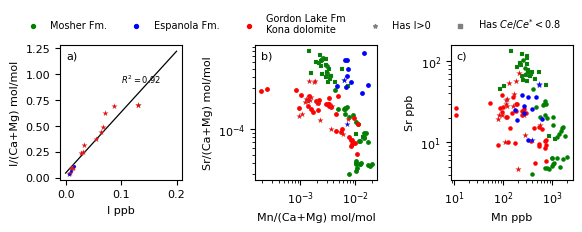

In [5]:
# Make additional cross plots
matplotlib.rc('xtick', labelsize=8) 
matplotlib.rc('ytick', labelsize=8)


def Sr_vs_Mn_ppm():
    '''Makes a plot of Sr vs Mn in ppm units'''
    # sample names
    all_samples = all_data['Sample Name'].unique()
    samples_gl = data_gl['Sample Name'].unique()
    samples_esp = data_espanola['Sample Name'].unique()
    samples_steep = data_steep['Sample Name'].unique()

    # samples with iodine
    samples_iodine = all_data[all_data['has_iodine']]['Sample Name'].unique()
    # samples with negative cerium anomalies
    samples_neg = all_data[all_data['Ce_anomaly_geom']<=0.8]['Sample Name'].unique()
    
    # read data in ppm units
    nitric_acid_runs_ppb = pd.read_csv('data/nitric_acid_runs_reduced_ppb.csv')

    # change Espanola samples names
    change_names = lambda x: x.replace('18-2-', '')
    nitric_acid_runs_ppb['Sample Name'] =\
         nitric_acid_runs_ppb['Sample Name'].apply(change_names)

    # filter samples to incude same samples as mol pero mol units
    nitric_acid_runs_ppb = nitric_acid_runs_ppb[
        nitric_acid_runs_ppb['Sample Name'].isin(all_samples)]

    # make plot
    sample_list = [samples_steep, samples_gl, samples_esp]
    colors = ['g', 'r', 'b']
    for i, samples in enumerate(sample_list):
        # filter samples by formation
        data_samples = nitric_acid_runs_ppb[nitric_acid_runs_ppb['Sample Name'].\
            isin(samples)]
        #  filter samples with idoine
        data_iodine = data_samples[data_samples['Sample Name'].\
            isin(samples_iodine)]
        #  filter samples without idoine
        data_no_iodine = data_samples[~data_samples['Sample Name'].\
            isin(samples_iodine)]
        #  filter samples without negative cerium anomalies
        data_no_neg = data_samples[~data_samples['Sample Name'].\
            isin(samples_neg)]
        #  filter samples with negative cerium anomalies
        data_neg = data_samples[data_samples['Sample Name'].\
            isin(samples_neg)]

        # x=Mn y=Sr
        x='55 -> 55  Mn  [ H2 ]'
        y = '88  Sr  [ No Gas ]'
        
        # for mosher samples plot data with and without ce anomalies with
        #  different markers
        if i ==0:
            plt.scatter(data_no_neg[x], data_no_neg[y],
                    color=colors[i], s=5)

            plt.scatter(data_neg[x], data_neg[y],
                color=colors[i], s=10, marker='s', edgecolor='gray', 
                linewidth=0.1)
        # for espanola and gordon lake samples plot data with and without I with
        #  different markers
        else:
            plt.scatter(data_no_iodine[x], data_no_iodine[y],
                    color=colors[i], s=5)

            plt.scatter(data_iodine[x], data_iodine[y],
                color=colors[i], s=20, marker='*', edgecolor='gray', 
                linewidth=0.1)


def plot_data(x, y, only_iodine=False, s=6):
    '''Makes a cross plot'''
    df_list = [data_steep, data_espanola, data_gl]
    colors = ['g', 'b', 'r' ]
    factor = 1e6 if y == I_str else 1
    for i, df in enumerate(df_list):
        df['Mn/Sr'] = df['55 -> 55  Mn  [ H2 ]'] / df['88  Sr  [ No Gas ]']
        df_iodine = df[df.has_iodine]
        df_no_iodine = df[~df.has_iodine]
        if i==0:
            df_neg = df[df.Ce_anomaly_geom < 0.8]
            df_no_neg = df[df.Ce_anomaly_geom >= 0.8]
            plt.scatter(df_no_neg[x], df_no_neg[y],
                    color=colors[i], s=s)
            plt.scatter(df_neg[x], df_neg[y],
                color=colors[i], s=s*2, marker="s", edgecolor='gray', linewidth=0.1)
        else:
            if not only_iodine:
                plt.scatter(df_no_iodine[x], df_no_iodine[y]*factor,
                    color=colors[i], s=s)
            plt.scatter(df_iodine[x], df_iodine[y]*factor,
                color=colors[i], s=s*3, marker='*', edgecolor='gray', linewidth=0.1)
            
fig, axs = plt.subplots(1,3, figsize=(a4_x*0.8, a4_y*0.15))

plt.sca(axs[0])
I_vs_I()
axs[0].text(0.05, 0.9, str('a)'), transform=axs[0].transAxes, size=8)
plt.xlabel('I ppb', fontsize=8)
plt.ylabel('I/(Ca+Mg) mol/mol', fontsize=8)

plt.sca(axs[1])
plot_data('55 -> 55  Mn  [ H2 ]', '88  Sr  [ No Gas ]')
plt.xlabel('Mn/(Ca+Mg) mol/mol', fontsize=8)
plt.ylabel('Sr/(Ca+Mg) mol/mol', fontsize=8)
axs[1].text(0.05, 0.9, str('b)'), transform=axs[1].transAxes, size=8)
plt.yscale('log')
plt.xscale('log')

plt.sca(axs[2])
Sr_vs_Mn_ppm()
axs[2].text(0.05, 0.9, str('c)'), transform=axs[2].transAxes, size=8)
plt.xlabel('Mn ppb', fontsize=8)
plt.ylabel('Sr ppb', fontsize=8)
plt.yscale('log')
plt.xscale('log')


plt.subplots_adjust(wspace=0.6, hspace=1)

def make_handles(m,c,s, alpha=None, edgecolor=None, linewidth=None):
        return plt.scatter([],[],marker=m, s=s, color=c, alpha=alpha,
             edgecolor=None, linewidth=None)
handles = [make_handles("o","g", 8)] + [make_handles("o","b", 8)]  +\
    [make_handles("o","r", 8)] + [make_handles("*","gray", 8)] + [make_handles("s","gray", 8)] 

legend_labels =[ "Mosher Fm.", "Espanola Fm.", "Gordon Lake Fm\nKona dolomite",
    "Has I>0",r'Has $Ce/Ce^{*} < 0.8$']

plt.legend(handles, legend_labels, fontsize=7, frameon=0,
    loc='upper center', ncol=5, bbox_to_anchor=(-1.3, 1.3))

plt.savefig('plots/cross_plots_additional.pdf',  bbox_inches='tight')

In [6]:
def get_REE_data(data, oxide_corrected=True):
    '''Gets REE/PAAS sample data'''

    # melt data
    id_vars = ['Sample Name', 'formation', 'neg_Ce_anomaly', 'pos_Ce_anomaly',
        'has_iodine']

    data_melt = data.melt(id_vars=id_vars, 
        var_name='element_description', value_name='conc')

    
    paas = get_PAAS_data()
    elements = paas.element.unique()

    def get_element(x):
        splited = x.split('  ')
        if len(splited) > 1:
            return splited[1]
        else:
            return x

    # exclude '89 -> 105  Y  [ O2 ]'
    data_melt = data_melt[data_melt.element_description != '89 -> 105  Y  [ O2 ]']
    
    # find elements that are oxide corrected
    is_oxide_corrected = [x for x in  data_melt.element_description.unique()
        if 'oxide_corrected' in x]
    if oxide_corrected:
        # delete non corrected data
        not_oxide_corrected = [x.replace(' oxide_corrected', '') for x
            in is_oxide_corrected]
        data_melt = data_melt[~data_melt.element_description.isin(
            not_oxide_corrected)]
    else:
        # else delete corrected data
        data_melt = data_melt[~data_melt.element_description.isin(
            is_oxide_corrected)]

    data_melt['element'] = data_melt.element_description.apply(get_element)
    data_melt = data_melt[data_melt.element.isin(elements)]
    data_melt = pd.merge(data_melt, paas, on='element', how='left')
    # normalize to PAAS
    data_melt['Sample/PAAS'] =\
        data_melt['conc'] / data_melt['paas/Ca+Mg_mol_per_mol']
    data_melt['Sample/PAAS'] = pd.to_numeric(data_melt['Sample/PAAS'])
    
    # sort data by element
    element_order = {elements[i]:i for i in range(len(elements))}
    data_melt['element_oder'] = data_melt.element.map(element_order)
    data_melt = data_melt.sort_values(['Sample Name', 'element_oder'])
    return data_melt

ree_data = get_REE_data(all_data)

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/684282932.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['element_oder'] = data.element.map(element_order)
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/684282932.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['element_oder'] = data.element.map(element_order)
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/684282932.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a

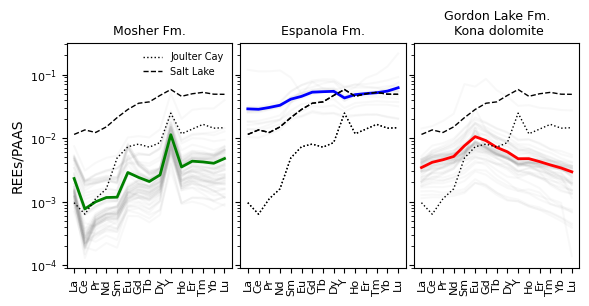

In [7]:
def plot_data(formation, color):
    '''Makes a REE pattern plot'''

    data = ree_data[ree_data.formation==formation]
    elements = data.element.unique()
    element_order = {elements[i]:i for i in range(len(elements))}


    data['element_oder'] = data.element.map(element_order)
    data = data.sort_values(['element_oder'])

    mean_data = data[['element','Sample/PAAS']].groupby('element').mean().reset_index()
    mean_data['element_oder'] = mean_data.element.map(element_order)
    mean_data = mean_data.sort_values(['element_oder'])

    for sample in data['Sample Name'].unique():
        data_s = data[data['Sample Name'] == sample]
        plt.plot(data_s.element, data_s['Sample/PAAS'],
            color='gray', alpha=0.05)
    plt.plot(mean_data.element, mean_data['Sample/PAAS'],
        color=color, lw=2)

# modern carbonates REE data
joulter_cays = pd.read_csv('data/REE_Joulter_Cays_Li_2019_ppm.csv').mean().\
    reset_index().rename(columns={'index': 'element', 0:'ppm'})
# Moder lake carbonate data
salt_lake = pd.read_csv('data/REE_Salt_lake_Li_2019_ppm.csv').mean().\
    reset_index().rename(columns={'index': 'element', 0:'ppm'})

# normalize to PAAS
paas = get_PAAS_data().reset_index()
joulter_cays_paas = joulter_cays.ppm/paas.ppm
salt_lake_paas = salt_lake.ppm/paas.ppm

# Make REE plots
fig, axs = plt.subplots(1,3, figsize=(0.8*a4_x, 0.25*a4_y), sharey=True, sharex=True)

plt.sca(axs[0])
plot_data('Steep Rock', 'g')
plt.plot(joulter_cays.element, joulter_cays_paas, color='k', lw=1, ls=':',
    label='Joulter Cay')
plt.plot(salt_lake.element, salt_lake_paas, color='k', lw=1, ls='--',
    label='Salt Lake')
plt.xticks( rotation=90)
plt.ylabel('REEs/PAAS')
plt.legend(frameon=False, fontsize=7)
plt.title('Mosher Fm.', fontsize=9)

plt.sca(axs[1])
plot_data('Espanola', 'b')
plt.plot(joulter_cays.element, joulter_cays_paas, color='k', lw=1, ls=':',
    label='Joulter Cay')
plt.plot(salt_lake.element, salt_lake_paas, color='k', lw=1, ls='--',
    label='Salt Lake')
plt.plot(joulter_cays.element, joulter_cays_paas, color='k', lw=1, ls=':',
    label='Joulter Cay')
plt.plot(salt_lake.element, salt_lake_paas, color='k', lw=1, ls='--',
    label='Salt Lake')
plt.xticks( rotation=90)
plt.title('Espanola Fm.', fontsize=9)

plt.sca(axs[2])
plot_data('Gordon Lake', 'r')
plt.plot(joulter_cays.element, joulter_cays_paas, color='k', lw=1, ls=':',
    label='Joulter Cay')
plt.plot(salt_lake.element, salt_lake_paas, color='k', lw=1, ls='--',
    label='Salt Lake')
plt.title('Gordon Lake Fm.\n Kona dolomite', fontsize=9)


plt.yscale('log')
plt.subplots_adjust(wspace=0.05)
plt.xticks( rotation=90)

plt.savefig(f'plots/ree_patterns.pdf', dpi=300)

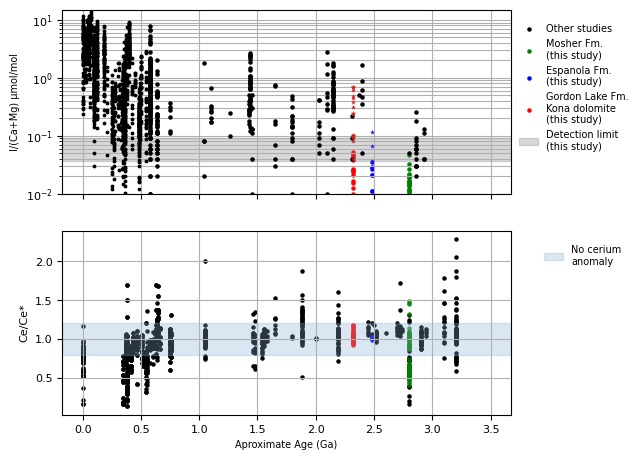

In [8]:
# Make Iodine and Cerium anomalies plots across Earth's history

# read Iodine data across Earth's history from different sources
data_liu = pd.read_excel('data/Liu_et_al_2010_iodine_data.xlsx')
data_liu = data_liu[['Approximate Ma', 'I/Ca (μmol/mol)']]
data_liu.columns = ['age', 'iodine']
data_liu['age'] = data_liu['age']/1e3

data_hardisty = pd.read_csv('data/hardisty_data', sep='|', names=['formation', 'iodine'])
ages_hardisty = pd.read_csv('data/hardisty_ages', sep='|', names=['formation', 'age'])
ages_hardisty = {k:v for k,v in zip(ages_hardisty.formation, ages_hardisty.age)}
data_hardisty['age'] = data_hardisty['formation'].map(ages_hardisty)
data_hardisty = data_hardisty[['age', 'iodine']]

data_hardisty_2017 = pd.read_csv('data/hardisty_2017_data', sep='\t')
ages_hardisty_2017 = pd.read_csv('data/hardisty_2017_ages', sep='\t')
ages_hardisty_2017 = {k:v for k,v in zip(ages_hardisty_2017['Geologic unit'],
    ages_hardisty_2017['age'])}
data_hardisty_2017['age'] = data_hardisty_2017['Formation'].map(ages_hardisty_2017)

data_hardisty_2017 = data_hardisty_2017[['age', 'I/(Ca+Mg) (μmol/mol)']]
data_hardisty_2017.columns = ['age', 'iodine']

fang_data = pd.read_csv('data/fang_data', sep='|')

# concatenate I data
data_iodine = pd.concat([data_hardisty, data_hardisty_2017, fang_data])

# read Ce anomaly data across Earth's history
data_tang = pd.read_excel('data/Tang_etal_2016.xls', skiprows=1)
data_tang = data_tang[['Age (Ga)', 'Ce/Ce*']]
data_tang.columns = ['Age', 'Ce_anomaly']
data_wallace_1 = pd.read_excel('data/Wallace_etal_2017.xlsx', sheet_name='Table 1-laser')
data_wallace_1 = data_wallace_1[['Approx. Age (Ma)', 'Ce/Ce* (4)']]
data_wallace_1.columns = ['Age', 'Ce_anomaly']
data_wallace_1['Age'] =  data_wallace_1['Age'] /1e3
data_wallace_2 = pd.read_excel('data/Wallace_etal_2017.xlsx', sheet_name='Table 1-laser')
data_wallace_2 = data_wallace_2[['Approx. Age (Ma)', 'Ce/Ce* (4)']]
data_wallace_2.columns = ['Age', 'Ce_anomaly']
data_wallace_2['Age'] =  data_wallace_2['Age'] /1e3
data_cerium = pd.concat([data_tang, data_wallace_1, data_wallace_2])

# I will assign these ages to the Formations
ages = {'Espanola': 2.48, 'Gordon Lake': 2.32, 'Steep Rock':2.8}
all_data ['age'] = all_data['formation'].map(ages)

# filter sample data by fromatiuon and I content
samples_wt_iodine_esp = all_data[(all_data.formation=='Espanola')]
samples_wt_iodine_esp = samples_wt_iodine_esp[~samples_wt_iodine_esp.has_iodine]
samples_wt_iodine_gl = all_data[all_data.formation=='Gordon Lake']
samples_wt_iodine_gl = samples_wt_iodine_gl[~samples_wt_iodine_gl.has_iodine]
samples_wt_iodine_sr = all_data[all_data.formation=='Steep Rock']
samples_wt_iodine_sr = samples_wt_iodine_sr[~samples_wt_iodine_sr.has_iodine]

samples_w_iodine_esp = all_data[(all_data.formation=='Espanola')]
samples_w_iodine_esp = samples_w_iodine_esp[samples_w_iodine_esp.has_iodine]
samples_w_iodine_gl = all_data[all_data.formation=='Gordon Lake']
samples_w_iodine_gl = samples_w_iodine_gl[samples_w_iodine_gl.has_iodine]
samples_w_iodine_sr = all_data[all_data.formation=='Steep Rock']
samples_w_iodine_sr = samples_w_iodine_sr[samples_w_iodine_sr.has_iodine]

fig, axs = plt.subplots(2,1, figsize=(a4_x*0.7, a4_y*0.45), sharex=True)

plt.sca(axs[0])
plt.grid(which='both', zorder=0)

# plot I data
plt.scatter(data_iodine['age'], data_iodine['iodine'], s=5, color='k',
    label='Other studies', zorder=5)
# this data is in I/Ca units not I/Ca+Mg. It is not straight forward to convert 
#  the units, but I do not think this will make a big difference
plt.scatter(data_liu['age'], data_liu['iodine'], s=3, color='k',
        zorder=3)
# plot sample data
plt.scatter(samples_w_iodine_esp['age'], 
    samples_w_iodine_esp['127  I  [ No Gas solution ]'] * 1e6, s=12, color='b',
     marker='*', zorder=5,
     edgecolor='gray', linewidth=0.1)
plt.scatter(samples_w_iodine_gl['age'], 
    samples_w_iodine_gl['127  I  [ No Gas solution ]'] * 1e6, s=12, color='r',
     marker='*', zorder=5,
     edgecolor='gray', linewidth=0.1)
plt.scatter(samples_w_iodine_sr['age'], 
    samples_w_iodine_sr['127  I  [ No Gas solution ]'] * 1e6, s=12, color='g',
     marker='*', zorder=5,
     edgecolor='gray', linewidth=0.1)

plt.scatter(samples_wt_iodine_sr['age'], 
    samples_wt_iodine_sr['127  I  [ No Gas solution ]'] * 1e6, s=5, color='g',
    zorder=0, label='Mosher Fm.\n(this study)')
plt.scatter(samples_wt_iodine_esp['age'], 
    samples_wt_iodine_esp['127  I  [ No Gas solution ]'] * 1e6, s=5, color='b',
    zorder=0, label='Espanola Fm.\n(this study)')
plt.scatter(samples_wt_iodine_gl['age'], 
    samples_wt_iodine_gl['127  I  [ No Gas solution ]'] * 1e6, s=5, color='r',
    zorder=0, label='Gordon Lake Fm.\nKona dolomite\n(this study)')

plt.yscale('log')
plt.ylim([1e-2, 15])

plt.ylabel('I/(Ca+Mg) µmol/mol', fontsize=7)
plt.axhspan(0.037, 0.09, alpha=0.3, color='gray', label='Detection limit\n(this study)')
plt.legend(fontsize=7, frameon=0, ncol=1, bbox_to_anchor=(1.14, 0.97),
           loc='upper center')

# plor cerium data
plt.sca(axs[1])
plt.grid(which='both', zorder=0)
plt.scatter(data_cerium.Age, data_cerium.Ce_anomaly, s=5, color='k')
plt.xlabel('Aproximate Age (Ga)', fontsize=7)
plt.ylabel('Ce/Ce*', fontsize=8)

data_ce_esp = all_data[(all_data.formation=='Espanola')]
data_ce_gl = all_data[(all_data.formation=='Gordon Lake')]
data_ce_steep = all_data[(all_data.formation=='Steep Rock')]

plt.scatter(data_ce_esp.age, data_ce_esp.Ce_anomaly_geom, s=6, color='b', alpha=0.6)
plt.scatter(data_ce_gl.age, data_ce_gl.Ce_anomaly_geom, s=6, color='r', alpha=0.6)
plt.scatter(data_ce_steep.age, data_ce_steep.Ce_anomaly_geom, s=6, color='g', alpha=0.6)
plt.axhspan(1.2, 0.8, alpha=0.3, color='#87B0D4', label='No cerium\nanomaly')

plt.legend(fontsize=7, frameon=0, ncol=1, bbox_to_anchor=(1.16, 0.97),
           loc='upper center')
plt.subplots_adjust(hspace=0.2)

plt.savefig('plots/iodine_over_time.pdf', bbox_inches='tight')

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/155441938.py:97: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  nitric_runs = pd.read_csv('data/nitric_acid_runs_reduced.csv')
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/299706071.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_espanola_['depth'] = data_espanola_['Sample Name'].apply(
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_76057/299706071.py:66: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user

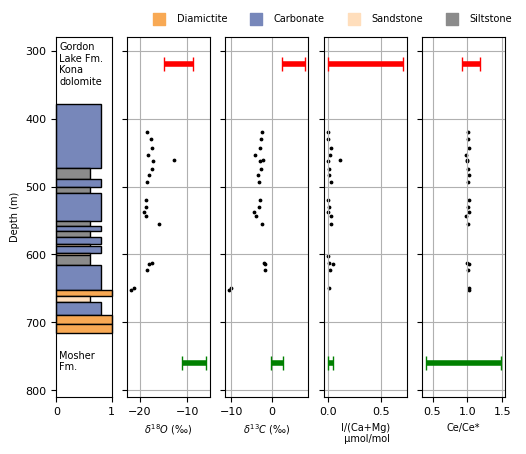

In [9]:
def plot_stratigraphy(ax, data, init_depth=0, linewidth=1,
        ascending=True):
    '''Makes a stratigraphic column plot'''
    
    data = data.sort_values('y0', ascending=ascending)

    total_thickness = data.thickness.sum()
    ax.set_ylim(init_depth,init_depth+total_thickness)

    # initiate counting of the stratigraphic height
    strat_height = init_depth

    # loop over elements of the data
    for i in range(data.shape[0]):

        # pull out the thickness
        this_thickness = data.iloc[i].thickness
        this_color = data.iloc[i].color_style
        this_width = data.iloc[i].width_style
        # create the rectangle
        ax.add_patch(Rectangle((0.0,strat_height), this_width, this_thickness,
                      facecolor=this_color, edgecolor='k', linewidth=linewidth))

        # count the stratigraphic height
        strat_height = strat_height + this_thickness

    # turning the spines off creates some clipping mask issues
    # so just turn the clipping masks off
    for obj in ax.findobj():
        obj.set_clip_on(False)

def add_stratigrahy_legend(fig, axs, data, x=0.5, y=0.08):
    facies_by_color = data[['facies', 'color_style']].drop_duplicates()
    handles, labels = [], []
    for i in range(facies_by_color.shape[0]):
        facies = facies_by_color.iloc[i].facies
        color = facies_by_color.iloc[i].color_style
        handle = plt.scatter([],[],marker='s', color=color, s=20)
        handles.append(handle)
        labels.append(facies)

    if len(axs.shape) == 1:
        axbox = axs[-1].get_position()
    else:
        axbox = axs[-1][1].get_position()
    # create legend
    leg = plt.legend(handles, labels, loc='lower center', ncol=len(handles),
        fontsize=7,
        bbox_to_anchor=[axbox.x0 + x*axbox.width, axbox.y0-y], 
        bbox_transform=fig.transFigure, frameon=False, title_fontsize=8,
        markerscale=2)

# read core depths
with open('data/espanola_cores_depths.json') as f:
    espanola_depths = json.load(f)
espanola_depths = {k.replace('18-2-', ''):v for k,v in espanola_depths.items()}
# read stratigraphy information
espanola_litho = pd.read_csv('data/espanola_lithostratigraphy.csv')

all_data = get_data_mol_per_mol()
data_espanola_ = all_data[all_data.formation == 'Espanola']

data_espanola_['depth'] = data_espanola_['Sample Name'].apply(
    lambda x: x[:x.find('-')]).map(espanola_depths)
get_core = lambda x: x[:x.find('-')]
data_espanola_['core'] = data_espanola_['Sample Name'].apply(get_core)

# if there are multiple drill holes in the sampe samples, averge the data
numeric_idx=[i for i,x in enumerate(data_espanola_.dtypes.to_list()) if x=='float64']
numeric_cols =data_espanola_.columns[numeric_idx].tolist()
numeric_cols.append('core')
data_espanola_ = data_espanola_[numeric_cols].groupby('core').mean().reset_index(drop=1)


# Make plot
def add_value_range(data, variable, ax, y, color='k', factor=1):
    datamin = data[variable].min() * factor
    datamax = data[variable].max() * factor
    middle = (datamin + datamax)/2
    plt.sca(ax)
    xerr=datamax-middle if datamax>middle else middle-datamax
    plt.errorbar(middle, y, xerr=xerr, color=color, capsize=5, linewidth=4)


# plot the Section using the Style
fig, ax = plt.subplots(1, 5, figsize=(a4_x*0.7, a4_y*0.4),
                       gridspec_kw={'width_ratios': [1, 1.5,1.5, 1.5, 1.5]},
                       sharey=False)
init_depth = espanola_litho.y1.min()

plt.sca(ax[0])
plot_stratigraphy(ax[0], espanola_litho, init_depth=init_depth, ascending=True)
plt.text(0.05, 770, 'Mosher\nFm.', fontsize=7)
plt.text(0.05, 350, 'Gordon\nLake Fm.\nKona\ndolomite', fontsize=7)
ax[0].set_ylabel('Depth (m)', fontsize=7)
plt.ylim([280, 810])
plt.gca().invert_yaxis()

plt.sca(ax[1])
plt.scatter(data_espanola_.d18o_sp, data_espanola_.depth, color='k', s=3)
add_value_range(data_gl, 'd18o_sp', ax[1], 320, color='r')
add_value_range(data_steep, 'd18o_sp', ax[1], 760, color='g')
plt.grid()
plt.xlabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax[1].invert_yaxis()
plt.ylim([810, 280])
ax[1].tick_params(axis='y', labelleft=False)

plt.sca(ax[2])
plt.scatter(data_espanola_.d13c_sp, data_espanola_.depth, color='k', s=3)
add_value_range(data_gl, 'd13c_sp', ax[2], 320, color='r')
add_value_range(data_steep, 'd13c_sp', ax[2], 760, color='g')
plt.xlabel(r'$\delta^{13}C$ (‰)', fontsize=7)
plt.grid()
ax[2].invert_yaxis()
plt.ylim([810, 280])
ax[2].tick_params(axis='y', labelleft=False)

plt.sca(ax[3])
plt.scatter(data_espanola_['127  I  [ No Gas solution ]'] * 1e6 , data_espanola_.depth, color='k', s=3)
add_value_range(data_gl, '127  I  [ No Gas solution ]', ax[3], 320, 
    color='r', factor=1e6)
add_value_range(data_steep, '127  I  [ No Gas solution ]', ax[3], 760,
    color='g', factor=1e6)
plt.xlabel(r'I/(Ca+Mg)'+'\n µmol/mol', fontsize=7)
plt.grid()
ax[3].invert_yaxis()
plt.ylim([810, 280])
ax[3].tick_params(axis='y', labelleft=False)

plt.sca(ax[4])
plt.scatter(data_espanola_['Ce_anomaly_geom'], data_espanola_.depth, color='k', s=3)
add_value_range(data_gl, 'Ce_anomaly_geom', ax[4], 320, 
    color='r', factor=1)
add_value_range(data_steep, 'Ce_anomaly_geom', ax[4], 760,
    color='g', factor=1)
plt.xlabel(r'Ce/Ce*', fontsize=7)
plt.grid()
ax[4].invert_yaxis()
plt.ylim([810, 280])
ax[4].tick_params(axis='y', labelleft=False)

# plt.ylim([290, 850])
# plt.yticks([700, 600, 500, 400])
add_stratigrahy_legend(fig, ax, espanola_litho, x=-1.1, y=-0.78)

plt.savefig('plots/stratigraphic_column.pdf')



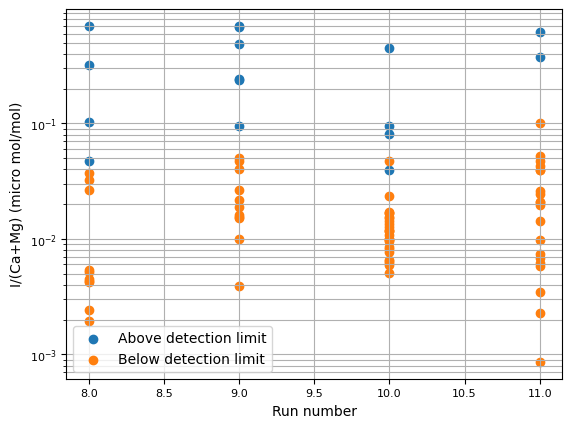

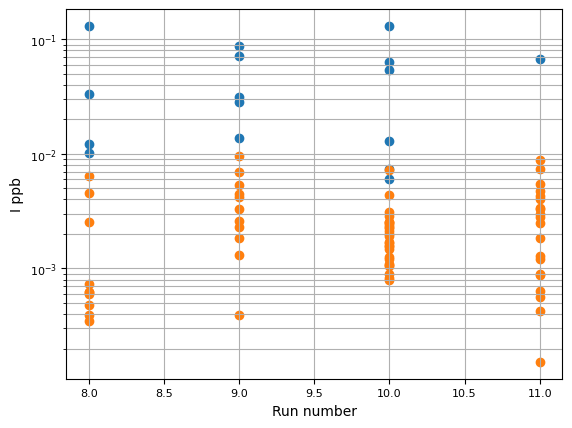

In [10]:
# Use a plot to I estimate detection limit
# read I data in mol/mol and ppb units
stabilizer_runs = pd.read_csv('data/stabilizer_runs_reduced.csv')
stabilizer_runs_ppb = pd.read_csv('data/stabilizer_runs_reduced_ppb.csv')
# filter I data
stabilizer_runs = stabilizer_runs[stabilizer_runs.element_description == I_str]
stabilizer_runs_ppb = stabilizer_runs_ppb[stabilizer_runs_ppb.element_description == I_str]

def starts_with_num(x):
        try:
            int(x[0])
        except:
            return False
        return True

def assign_formation(sample_name):
        if sample_name.startswith('SR'):
            return 'Steep Rock'
        elif sample_name.startswith('B'):
            return 'Gordon Lake'
        elif starts_with_num(sample_name):
            return 'Espanola'
        else:
            return 'Not sample'
        
# assign formation names
stabilizer_runs['formation'] = stabilizer_runs['Sample Name'].apply(assign_formation)
#  ignore standards
stabilizer_runs = stabilizer_runs[stabilizer_runs['formation'] != 'Not sample']
# ignore weird samples
stabilizer_runs = stabilizer_runs[~stabilizer_runs['Sample Name'].isin(['BRQ5-1 redo', 'BRQ5-1-unknown'])]
stabilizer_runs = stabilizer_runs[~stabilizer_runs['Sample Name'].isin(['19-6', 'BRQ3-1'])]
# ignore Al rich samples
carbonate_rich = all_data[all_data.is_carbonate_rich]['Sample Name'].unique()
stabilizer_runs = stabilizer_runs[stabilizer_runs['Sample Name'].isin(carbonate_rich)]

stabilizer_runs_ppb['formation'] = stabilizer_runs_ppb['Sample Name'].apply(assign_formation)
#  ignore standards
stabilizer_runs_ppb = stabilizer_runs_ppb[stabilizer_runs_ppb['formation'] != 'Not sample']
#  ignore weird samples
stabilizer_runs_ppb = stabilizer_runs_ppb[~stabilizer_runs_ppb['Sample Name'].isin(['BRQ5-1 redo', 'BRQ5-1-unknown'])]
stabilizer_runs_ppb = stabilizer_runs_ppb[~stabilizer_runs_ppb['Sample Name'].isin(['19-6', 'BRQ3-1'])]
#  ignore Al rich samples
carbonate_rich = all_data[all_data.is_carbonate_rich]['Sample Name'].unique()
stabilizer_runs_ppb = stabilizer_runs_ppb[stabilizer_runs_ppb['Sample Name'].isin(carbonate_rich)]


plt.figure()
conc='inferred_mol/mol'
plt.scatter(stabilizer_runs[stabilizer_runs.has_iodine]['run_id'], 
    stabilizer_runs[stabilizer_runs.has_iodine][conc]*1e6,
    label='Above detection limit')
plt.scatter(stabilizer_runs[~stabilizer_runs.has_iodine]['run_id'],
        stabilizer_runs[~stabilizer_runs.has_iodine][conc]*1e6,
        label='Below detection limit')
plt.xlabel('Run number')
plt.ylabel('I/(Ca+Mg) (micro mol/mol)')
plt.yscale('log')
plt.grid(which="both")
plt.legend()

plt.figure()
conc='inferred_ppb_zero_intercept'
plt.scatter(stabilizer_runs_ppb[stabilizer_runs_ppb.has_iodine]['run_id'], stabilizer_runs_ppb[stabilizer_runs_ppb.has_iodine][conc])
plt.scatter(stabilizer_runs_ppb[~stabilizer_runs_ppb.has_iodine]['run_id'], stabilizer_runs_ppb[~stabilizer_runs_ppb.has_iodine][conc])
plt.xlabel('Run number')
plt.ylabel('I ppb')
plt.yscale('log')
plt.grid(which="both")